# 04 · QAOA: assign sensors to two transmission slots

Run: [setup](../SETUP.md). Qiskit ideal simulation; saved outputs are local. Run your version in qBraid Lab (or implement it in Classiq).

**Input:** four sensors and five interfering pairs. **Output:** one bit per sensor assigning slot 0 or 1. Maximize the number of interfering pairs assigned different slots: the **MaxCut** score. This simplified model ignores slot capacities, packet timing, and changing interference.

Qiskit prints bits as `q3 q2 q1 q0`, here `D C B A`. For example, `0101` puts A and C in slot 1. We can check all 16 assignments classically.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
print("Qiskit", qiskit.__version__, "| ideal Statevector simulator")

n = 4
names = ["A", "B", "C", "D"]
edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]
strings = [format(k, f"0{n}b") for k in range(2**n)]
def score(s):
    bits = [int(b) for b in s[::-1]]  # index by sensor A, B, C, D
    return sum(bits[i] != bits[j] for i, j in edges)
scores = np.array([score(s) for s in strings])
optimum = int(scores.max())
print("Classical optimum:", optimum, "| random mean:", scores.mean())
print("Optimal strings (DCBA):", [s for s in strings if score(s) == optimum])

Qiskit 2.3.0 | ideal Statevector simulator
Classical optimum: 4 | random mean: 2.5
Optimal strings (DCBA): ['0101', '1010']


## Build and tune one layer

QAOA means **Quantum Approximate Optimization Algorithm**. This version has one layer (`p=1`):

1. **Prepare:** H gates give every assignment equal probability.
2. **Cost:** change phases according to the score. An amplitude's squared magnitude gives probability; its phase affects how amplitudes combine. Changing phase alone leaves probabilities unchanged.
3. **Mix:** rotations combine amplitudes, making some outcomes reinforce and others cancel.
4. **Tune:** ordinary Python tries two gate angles, gamma and beta, and keeps the largest expected score.

The simulator provides exact probabilities for this small grid search. Hardware would estimate averages from repeated measurements. This is not evidence of a speedup over classical optimization.

In [2]:
def state_at(gamma, beta):
    circuit = QuantumCircuit(n)
    circuit.h(range(n))
    for i, j in edges:
        # -gamma implements the cut-score phase, up to a global phase.
        circuit.rzz(-float(gamma), i, j)
    for q in range(n):
        circuit.rx(2 * float(beta), q)
    return Statevector.from_instruction(circuit)

best_mean = -1
for gamma in np.linspace(0, 2 * np.pi, 25):
    for beta in np.linspace(0, np.pi, 21):
        mean = float(state_at(gamma, beta).probabilities() @ scores)
        if mean > best_mean:
            best_mean, best_gamma, best_beta = mean, gamma, beta
print(f"525 angle pairs; best gamma={best_gamma:.3f}, beta={best_beta:.3f}")
print(f"Best tested expected score: {best_mean:.3f}; classical optimum: {optimum}")
assert best_mean <= optimum + 1e-10

525 angle pairs; best gamma=0.524, beta=1.885
Best tested expected score: 3.232; classical optimum: 4


## Change one setting

**Predict:** keep gamma fixed and set beta to zero, turning the mixer off. What happens to the probabilities?

A **shot** is one simulated preparation and measurement. Compare 1,024 shots with the exact expectation. The mean describes average quality; the best sampled score describes only the luckiest outcome. Even random guessing can find an optimum here.

In [3]:
shots = 1024
results = {}
for index, (label, beta) in enumerate([("Tuned", best_beta), ("Mixer off", 0)]):
    state = state_at(best_gamma, beta)
    state.seed(2026 + index)
    probabilities = state.probabilities()
    counts = state.sample_counts(shots)
    exact = float(probabilities @ scores)
    sampled = sum(score(s) * count for s, count in counts.items()) / shots
    best_string = max(counts, key=score)
    results[label] = (exact, sampled, best_string)
    print(f"{label:9s}: exact mean {exact:.3f}, sampled mean {sampled:.3f}, "
          f"best sampled score {score(best_string)}")
    assert sum(counts.values()) == shots and np.isclose(probabilities.sum(), 1)
assert np.allclose(state_at(best_gamma, 0).probabilities(), 1 / 2**n)
print("Control checked: with mixing off, probabilities remain uniform.")

Tuned    : exact mean 3.232, sampled mean 3.229, best sampled score 4
Mixer off: exact mean 2.500, sampled mean 2.509, best sampled score 4
Control checked: with mixing off, probabilities remain uniform.


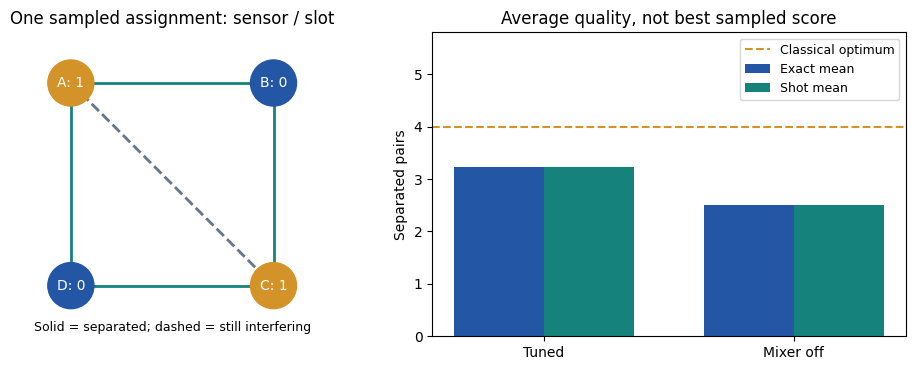

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
positions = np.array([[-1, 1], [1, 1], [1, -1], [-1, -1]])
bits = [int(b) for b in results["Tuned"][2][::-1]]
for i, j in edges:
    cut = bits[i] != bits[j]
    axes[0].plot(*positions[[i, j]].T, color="#16827c" if cut else "#65758b",
                 linestyle="-" if cut else "--", linewidth=2)
axes[0].scatter(*positions.T, s=1100,
                c=["#2456a6" if b == 0 else "#d39328" for b in bits], zorder=2)
for i, (x, y) in enumerate(positions):
    axes[0].text(x, y, f"{names[i]}: {bits[i]}", ha="center", va="center", color="white")
axes[0].set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal",
            title="One sampled assignment: sensor / slot")
axes[0].axis("off")
axes[0].text(0, -1.45, "Solid = separated; dashed = still interfering", ha="center", fontsize=9)
x = np.arange(len(results))
axes[1].bar(x - 0.18, [r[0] for r in results.values()], 0.36, label="Exact mean", color="#2456a6")
axes[1].bar(x + 0.18, [r[1] for r in results.values()], 0.36, label="Shot mean", color="#16827c")
axes[1].axhline(optimum, color="#d39328", linestyle="--", label="Classical optimum")
axes[1].set(xticks=x, xticklabels=list(results), ylim=(0, optimum + 1.8),
            ylabel="Separated pairs", title="Average quality, not best sampled score")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

**Try:** choose another beta, predict the change, and rerun the comparison. Or change one edge and rerun everything. Does the old assignment remain optimal?

Sources: [original QAOA paper](https://arxiv.org/abs/1411.4028); [Qiskit Statevector](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector).